# NumCompute-Stream demo: a buffered decision tree on a sensor stream

This notebook walks through the whole framework on a CSV stream:

1. load the CSV with our own I/O module (`numcompute_stream.io`),
2. look at it with streaming statistics (`StreamingStats.update_stats`),
3. split it into chunks to simulate data arriving over time,
4. train a pipeline incrementally with `.partial_fit()` through `StreamTrainer`,
5. log and plot the metrics over time with `numcompute_stream.visualise`.

**Data.** `data/room_occupancy_stream.csv` is a synthetic smart-building stream
(8000 readings, one every 10 minutes) made by `data/make_stream_dataset.py`. The
label is how busy a meeting room is: 0 empty, 1 a few people, 2 busy. It contains
three things a real stream has: missing sensor values, a category (`holiday`)
that first appears late, and **concept drift at row 5000**, when the light sensor
is replaced by one that reads about 40% lower.

Only NumPy and matplotlib are used.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "numcompute_stream").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import numcompute_stream as ncs
from numcompute_stream import visualise as vis

DATA = ROOT / "demo" / "data" / "room_occupancy_stream.csv"
FIGS = ROOT / "demo" / "figures"
FIGS.mkdir(exist_ok=True)
np.set_printoptions(precision=3, suppress=True)
print("numcompute_stream", ncs.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__)

numcompute_stream 0.2.0 | numpy 2.5.3 | matplotlib 3.11.2


## 1. Load the CSV with the custom I/O module

`load_dataset` reads the header, infers which columns are numeric (empty cells
become `NaN`) and which are text, and separates the target column.

In [2]:
data = ncs.load_dataset(DATA, target="occupancy")
print("numeric features    :", data.num_names)
print("categorical features:", data.cat_names)
print("X_num", data.X_num.shape, "| X_cat", data.X_cat.shape, "| y", data.y.shape)
print("missing values per numeric column:", np.isnan(data.X_num).sum(axis=0))
print("class counts (0 empty, 1 few, 2 busy):", np.bincount(data.y))
print("first row with day_type == 'holiday':", int(np.flatnonzero(data.X_cat[:, 0] == "holiday")[0]))

numeric features    : ['hour', 'temperature', 'humidity', 'light', 'co2', 'noise_db']
categorical features: ['day_type']
X_num (8000, 6) | X_cat (8000, 1) | y (8000,)
missing values per numeric column: [  0 246 232 223 243 245]
class counts (0 empty, 1 few, 2 busy): [4225 2635 1140]
first row with day_type == 'holiday': 5760


## 2. Streaming statistics

`StreamingStats` never stores the data: each `update_stats(chunk)` merges the
chunk's per-feature count, mean and M2 into the running totals (Chan/Welford),
and quantiles come from a fixed-size histogram per feature. Below the result after
80 chunks is checked against NumPy on the full array, and a sliding-window version
(last 10 chunks) shows the light-sensor drift.

In [3]:
full = ncs.StreamingStats(bins=128)
recent = ncs.StreamingStats(bins=128, window=10)
light_mean_window = []
for X_num, _, _ in ncs.stream_dataset(DATA, "occupancy", chunk_size=100):
    full.update_stats(X_num)
    recent.update_stats(X_num)
    light_mean_window.append(recent.mean[data.num_names.index("light")])

print("chunks seen:", full.n_chunks_)
print("streaming mean :", full.mean)
print("numpy nanmean  :", np.nanmean(data.X_num, axis=0))
print("max |difference| in variance:", np.max(np.abs(full.var - np.nanvar(data.X_num, axis=0))))
print("estimated medians:", full.quantile(0.5))
print("exact medians    :", np.nanmedian(data.X_num, axis=0))

chunks seen: 80
streaming mean : [ 11.447  21.429  41.489 185.576 519.027  35.494]
numpy nanmean  : [ 11.447  21.429  41.489 185.576 519.027  35.494]
max |difference| in variance: 1.5279510989785194e-10
estimated medians: [ 10.976  21.208  41.358 105.227 466.262  34.778]
exact medians    : [ 11.   21.2  41.4 104.2 466.2  34.8]


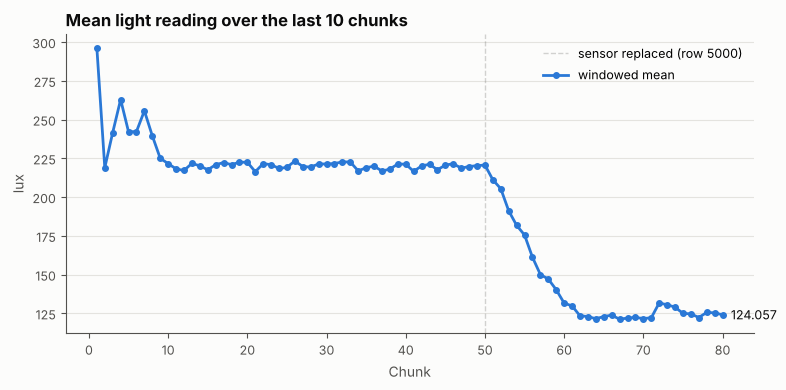

In [4]:
vis.plot_metric_over_time(
    light_mean_window, title="Mean light reading over the last 10 chunks",
    ylabel="lux", label="windowed mean", retrain_points=[50],
    event_label="sensor replaced (row 5000)", save_path=FIGS / "light_drift.png");

## 3. Simulate the stream and build the pipeline

The CSV is read again **chunk by chunk** with `stream_dataset` (100 rows per
chunk, 80 chunks), so at no point does the training loop hold the whole file.

The pipeline:

* `ColumnTransformer` sends the six numeric columns to `Imputer` (running mean)
  then `StandardScaler` (running mean/variance), and `day_type` to
  `OneHotEncoder`, which adds a column when it meets a new category.
* `DecisionTreeClassifier(max_depth=6, buffer_size=500)` buffers the incoming
  rows and retrains from scratch every time 500 rows have arrived.
  `accept_new_features=True` lets it accept the extra one-hot column.

`StreamTrainer` evaluates **test-then-train**: every chunk is first predicted by
the current tree, then used for training, so all scores are on unseen data.

In [5]:
NUM = list(range(len(data.num_names)))
CAT = [len(data.num_names)]


def make_pipeline(buffer_size=500, max_depth=6, criterion="gini"):
    prep = ncs.ColumnTransformer([
        ("num", ncs.Pipeline([("impute", ncs.Imputer(strategy="mean")),
                              ("scale", ncs.StandardScaler())]), NUM),
        ("cat", ncs.OneHotEncoder(handle_unknown="ignore"), CAT),
    ])
    tree = ncs.DecisionTreeClassifier(max_depth=max_depth, buffer_size=buffer_size,
                                      criterion=criterion, accept_new_features=True)
    return ncs.Pipeline([("prep", prep), ("tree", tree)])


def csv_stream(chunk_size=100):
    """(X, y) chunks straight from the CSV; X mixes numbers and text."""
    for X_num, X_cat, y in ncs.stream_dataset(DATA, "occupancy", chunk_size=chunk_size):
        yield np.column_stack([X_num.astype(object), X_cat]), y


def make_metrics():
    return {
        "accuracy": ncs.StreamingAccuracy(),
        "rolling_accuracy": ncs.StreamingAccuracy(window=5),
        "f1_macro": ncs.StreamingF1(average="macro"),
        "auc_ovr": ncs.StreamingAUC(classes=[0, 1, 2]),
        "confusion": ncs.StreamingConfusionMatrix(),
    }


pipe = make_pipeline(buffer_size=500)
print(pipe.named_steps["tree"])

DecisionTreeClassifier(max_depth=6, min_samples_split=2, max_features=None, criterion='gini', buffer_size=500, split_method='vectorised')


### Before the first retrain the tree cannot predict

This is a deliberate design choice: predicting with an untrained model would be
a guess, so `predict` raises `NotFittedError` and tells you how far the buffer is.

In [6]:
first_X, first_y = next(csv_stream())
pipe.partial_fit(first_X, first_y)
try:
    pipe.predict(first_X)
except ncs.NotFittedError as err:
    print("NotFittedError:", err)
pipe = make_pipeline(buffer_size=500)        # start again from nothing

NotFittedError: This DecisionTreeClassifier has not been trained yet: call fit(), or keep calling partial_fit() until 500 samples are buffered (currently 100), or call flush().


## 4. Train incrementally with `.partial_fit()` and log every chunk

In [7]:
trainer = ncs.StreamTrainer(pipe, metrics=make_metrics(), verbose=True)
history = trainer.run(csv_stream(chunk_size=100), max_chunks=12)   # first 12 chunks, printed

chunk   1 | seen    100 | acc nan | cum nan | retrains  0   | buffer   100 | mem 13.4 KiB
chunk   2 | seen    200 | acc nan | cum nan | retrains  0   | buffer   200 | mem 19.6 KiB
chunk   3 | seen    300 | acc nan | cum nan | retrains  0   | buffer   300 | mem 25.9 KiB
chunk   4 | seen    400 | acc nan | cum nan | retrains  0   | buffer   400 | mem 32.2 KiB
chunk   5 | seen    500 | acc nan | cum nan | retrains  1 * | buffer     0 | mem 12.4 KiB
chunk   6 | seen    600 | acc 0.840 | cum 0.840 | retrains  1   | buffer   100 | mem 18.8 KiB
chunk   7 | seen    700 | acc 0.800 | cum 0.820 | retrains  1   | buffer   200 | mem 25.0 KiB
chunk   8 | seen    800 | acc 0.800 | cum 0.813 | retrains  1   | buffer   300 | mem 32.2 KiB
chunk   9 | seen    900 | acc 0.800 | cum 0.810 | retrains  1   | buffer   400 | mem 39.2 KiB
chunk  10 | seen   1000 | acc 0.720 | cum 0.792 | retrains  2 * | buffer     0 | mem 11.4 KiB
chunk  11 | seen   1100 | acc 0.830 | cum 0.798 | retrains  2   | buffer   100 |

`*` marks a chunk that triggered a retrain: the buffer fills over 5 chunks of 100
rows, the tree retrains, the buffer empties. Chunks 1-5 are not scored because no
tree exists yet. Next, the full stream of 80 chunks is processed once with a fresh
pipeline (printing turned off) and the log is summarised.

In [8]:
pipe = make_pipeline(buffer_size=500)
trainer = ncs.StreamTrainer(pipe, metrics=make_metrics())
trainer.run(csv_stream(chunk_size=100))
log = trainer.format_log().splitlines()
print("\n".join(log[:9] + ["   ..."] + log[-4:]))
print()
for key, value in trainer.summary().items():
    if np.ndim(value) == 0:
        print(f"{key:>22}: {value:.4f}" if isinstance(value, float) else f"{key:>22}: {value}")

chunk  n_seen  chunk_accuracy  cumulative_accuracy  retrained  n_buffered  memory_bytes
    1     100             nan                  nan      False         100         13644
    2     200             nan                  nan      False         200         20044
    3     300             nan                  nan      False         300         26472
    4     400             nan                  nan      False         400         32872
    5     500             nan                  nan       True           0         12669
    6     600          0.8400               0.8400      False         100         19161
    7     700          0.8000               0.8200      False         200         25561
    8     800          0.8000               0.8133      False         300         32885
   ...
   77    7700          0.8100               0.8032      False         200         31049
   78    7800          0.8600               0.8040      False         300         39049
   79    7900          0.

In [9]:
tree = pipe.named_steps["tree"]
print("retrains:", tree.n_retrains_, "| rows still in buffer:", tree.n_buffered_)
print("last tree: depth", tree.get_depth(), "leaves", tree.get_n_leaves())
enc = pipe.named_steps["prep"].transformers[1][1]
print("one-hot columns learned:", enc.get_feature_names(["day_type"]))
print("retrain log (first 3):")
for r in tree.retrain_log_[:3]:
    print(f"   retrain {r['retrain']}: {r['n_samples']} rows, {r['seconds'] * 1000:.1f} ms, "
          f"depth {r['depth']}, {r['n_leaves']} leaves")

retrains: 16 | rows still in buffer: 0
last tree: depth 6 leaves 32
one-hot columns learned: ['day_type=weekday', 'day_type=weekend', 'day_type=holiday']
retrain log (first 3):
   retrain 1: 500 rows, 7.7 ms, depth 6, 44 leaves
   retrain 2: 500 rows, 6.4 ms, depth 6, 31 leaves
   retrain 3: 500 rows, 6.3 ms, depth 6, 32 leaves


## 5. Visualise the metrics over time

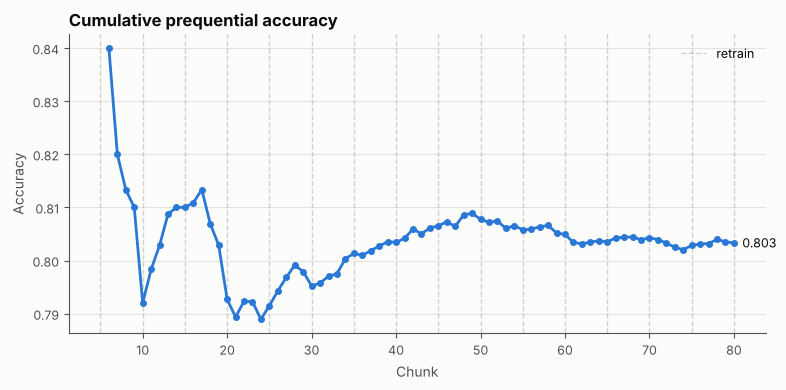

In [10]:
vis.plot_metric_over_time(
    trainer.get_log("accuracy"), title="Cumulative prequential accuracy",
    ylabel="Accuracy", retrain_points=trainer.get_log("retrained"),
    save_path=FIGS / "cumulative_accuracy.png");

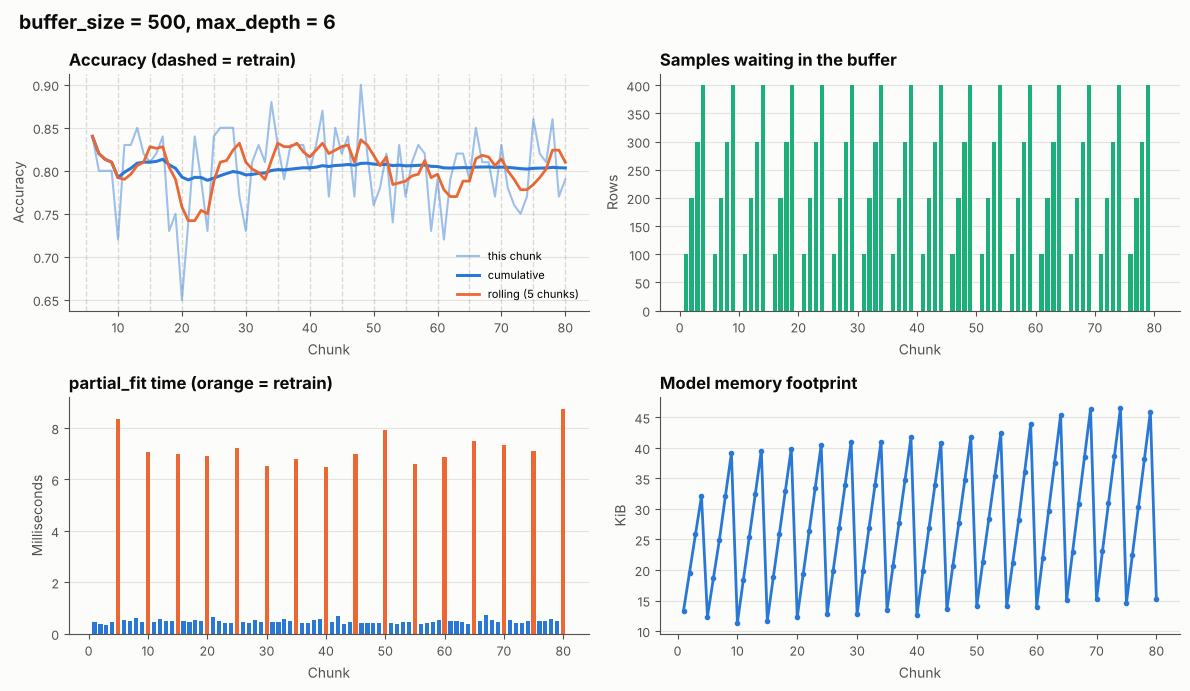

In [11]:
vis.plot_stream_dashboard(trainer, title="buffer_size = 500, max_depth = 6",
                          save_path=FIGS / "dashboard.png");

### Comparing models: what does `buffer_size` change?

Two identical pipelines except for `buffer_size`. A small buffer retrains often on
little data; a large one retrains rarely on more data. The rolling accuracy over
the last 5 chunks shows both the level and how each reacts to the drift at
chunk 50.

buffer_size  200: cumulative accuracy 0.763, macro F1 0.747, retrains 40, total fit time 197 ms


buffer_size  500: cumulative accuracy 0.803, macro F1 0.797, retrains 16, total fit time 216 ms


buffer_size 2000: cumulative accuracy 0.833, macro F1 0.824, retrains  4, total fit time 173 ms


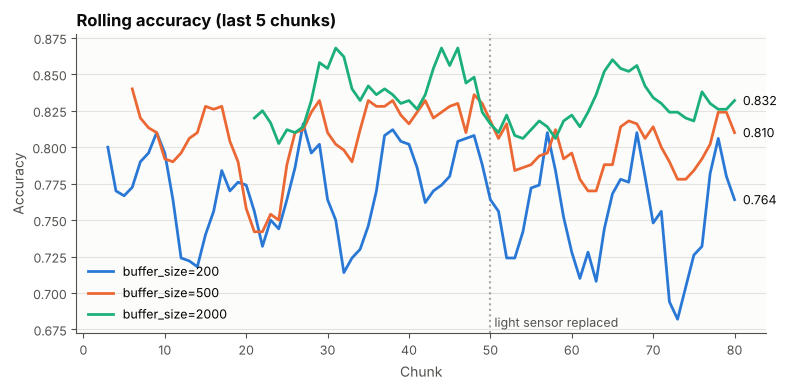

In [12]:
runs = {}
for bs in (200, 500, 2000):
    t = ncs.StreamTrainer(make_pipeline(buffer_size=bs), metrics=make_metrics())
    t.run(csv_stream(chunk_size=100))
    runs[bs] = t
    s = t.summary()
    print(f"buffer_size {bs:>4}: cumulative accuracy {s['accuracy']:.3f}, "
          f"macro F1 {s['f1_macro']:.3f}, retrains {s['retrains']:>2}, "
          f"total fit time {s['total_fit_seconds'] * 1000:.0f} ms")

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvline(50, color="#52514e", alpha=0.5, linestyle=":")
ax.text(50.5, 0.02, "light sensor replaced", transform=ax.get_xaxis_transform(),
        fontsize=9, color="#52514e")
vis.compare_models(
    runs[200].get_log("rolling_accuracy"), runs[500].get_log("rolling_accuracy"),
    labels=("buffer_size=200", "buffer_size=500"),
    extra={"buffer_size=2000": runs[2000].get_log("rolling_accuracy")},
    title="Rolling accuracy (last 5 chunks)", ylabel="Accuracy", ax=ax,
    save_path=FIGS / "compare_buffer_sizes.png");

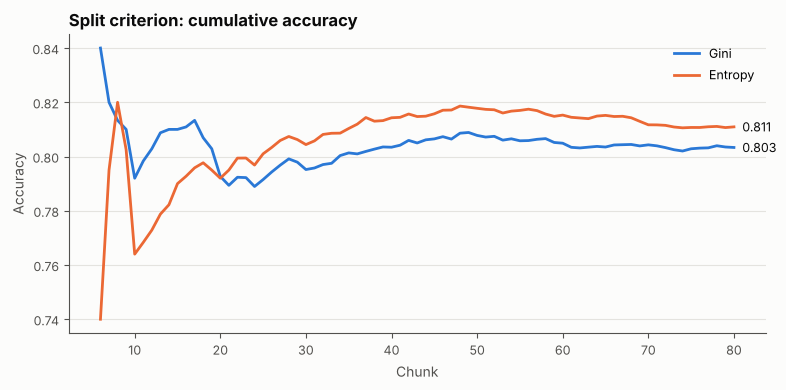

In [13]:
gini_run = runs[500]
ent = ncs.StreamTrainer(make_pipeline(buffer_size=500, criterion="entropy"), metrics=make_metrics())
ent.run(csv_stream(chunk_size=100))
vis.compare_models(gini_run.get_log("accuracy"), ent.get_log("accuracy"),
                   labels=("Gini", "Entropy"), title="Split criterion: cumulative accuracy",
                   ylabel="Accuracy", save_path=FIGS / "compare_criterion.png");

## 6. Predictions vs ground truth on the latest chunk

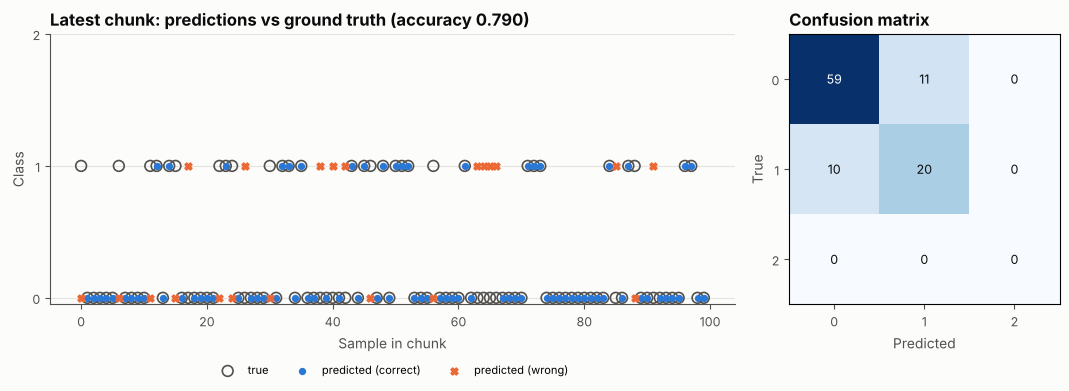

In [14]:
vis.plot_predictions_vs_ground_truth(
    trainer.last_y_true_, trainer.last_y_pred_, labels=[0, 1, 2],
    save_path=FIGS / "latest_chunk.png");

confusion matrix accumulated over the whole stream (rows = true):
[[3469  536    0]
 [ 598 1707  153]
 [   0  188  849]]
one-vs-rest AUC over the stream: 0.8699


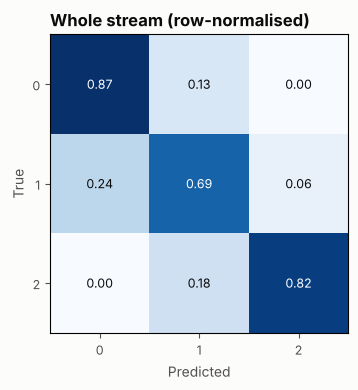

In [15]:
cm = trainer.metrics["confusion"]
print("confusion matrix accumulated over the whole stream (rows = true):")
print(cm.result())
print("one-vs-rest AUC over the stream:", round(trainer.metrics["auc_ovr"].result(), 4))
vis.plot_confusion_matrix(cm.result(), cm.labels_, normalize=True,
                          title="Whole stream (row-normalised)",
                          save_path=FIGS / "confusion_stream.png");

## 7. Streaming results equal batch results

The streaming metrics are exact, not approximations: on the same predictions they
give the same numbers as the batch functions from Assignment 2.1.

In [16]:
scored = [r for r in trainer.history_ if r["scored"]]
t2 = ncs.StreamTrainer(make_pipeline(buffer_size=500), metrics=make_metrics())
ys, ps = [], []
for X, y in csv_stream(100):
    rec = t2.score_chunk(X, y)
    if rec["scored"]:
        ys.append(y); ps.append(t2.last_y_pred_)
    t2.fit_chunk(X, y)
ys, ps = np.concatenate(ys), np.concatenate(ps)
print("streaming accuracy:", t2.metrics["accuracy"].result(), "| batch:", ncs.accuracy_score(ys, ps))
print("streaming macro F1:", t2.metrics["f1_macro"].result(), "| batch:", ncs.f1_score(ys, ps, average="macro"))
print("confusion matrices equal:", np.array_equal(t2.metrics["confusion"].result(), ncs.confusion_matrix(ys, ps)))

streaming accuracy: 0.8033333333333333 | batch: 0.8033333333333333
streaming macro F1: 0.7968592798017479 | batch: 0.7968592798017479
confusion matrices equal: True


## Summary

* The whole stream was read from CSV in 100-row chunks and never held by the
  training loop at once.
* Every component learned incrementally: imputer means, scaler mean/variance,
  one-hot categories (the `holiday` column appeared mid-stream), and the tree
  through buffered retraining.
* `buffer_size` is a trade-off: larger buffers give better trees and fewer
  retrains, but each retrain costs more and the model waits longer before it
  reacts to drift. The benchmark folder measures this systematically.

Figures are saved in `demo/figures/`.